Importing the Dependencies

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import joblib
from pathlib import Path


## Exploration & Data loading

In [3]:
df = pd.read_csv(r'A:\svm\notebook\telco_raw_data.csv')
df.shape

FileNotFoundError: [Errno 2] No such file or directory: 'A:\\svm\\notebook\\telco_raw_data.csv'

In [ ]:
pd.set_option('display.max_columns', None)  # Show all columns in the DataFrame
pd.set_option('display.max_rows', None)     # Show all rows in the DataFrame

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


- based on the .describe (and exploration) we can see that most categorical variables have between 2, 3, or 4 categories
- So for those that only have 2 (binary) let's just replace by 0 and 1
- For those that have 3 or 4 we can do One-Hot encoding

In [ ]:
# Clean and encode the raw customer data, then prepare scaled train/test sets.
df = df.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

binary_cols = [
    'gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn'
]
for column in binary_cols:
    if column in df.columns:
        df[column] = df[column].replace({
            'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0
        })

multi_cat_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod'
]
existing_multi_cat_cols = [column for column in multi_cat_cols if column in df.columns]
if existing_multi_cat_cols:
    df = pd.get_dummies(df, columns=existing_multi_cat_cols, drop_first=True)

bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)
df['Churn'] = df['Churn'].astype(int)

no_internet_cols = [
    column for column in df.columns if column.endswith('_No internet service')
]
if no_internet_cols:
    df['No_internet_service'] = df[no_internet_cols].any(axis=1).astype(int)
    df = df.drop(columns=no_internet_cols)

if 'MultipleLines_No phone service' in df.columns:
    df['No_phone_service'] = df['MultipleLines_No phone service'].astype(int)
    df = df.drop(columns=['MultipleLines_No phone service'])

X = df.drop(columns=['Churn'])
clean_df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=['TotalCharges'])
X_clean = clean_df.drop(columns=['Churn'])
y_clean = clean_df['Churn']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)
scaler = StandardScaler() #scale
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)


In [ ]:
corr_matrix = df.corr(numeric_only=True)
churn_corr = corr_matrix['Churn'].sort_values(ascending=False)
print(corr_matrix)

                                       SeniorCitizen    tenure  \
SeniorCitizen                               1.000000  0.015683   
tenure                                      0.015683  1.000000   
MonthlyCharges                              0.219874  0.246862   
TotalCharges                                0.102411  0.825880   
Churn                                       0.150541 -0.354049   
MultipleLines_Yes                           0.142996  0.332399   
InternetService_Fiber optic                 0.254923  0.017930   
InternetService_No                         -0.182519 -0.037529   
OnlineSecurity_Yes                         -0.038576  0.328297   
OnlineBackup_Yes                            0.066663  0.361138   
DeviceProtection_Yes                        0.059514  0.361520   
TechSupport_Yes                            -0.060577  0.325288   
StreamingTV_Yes                             0.105445  0.280264   
StreamingMovies_Yes                         0.119842  0.285402   
Contract_O

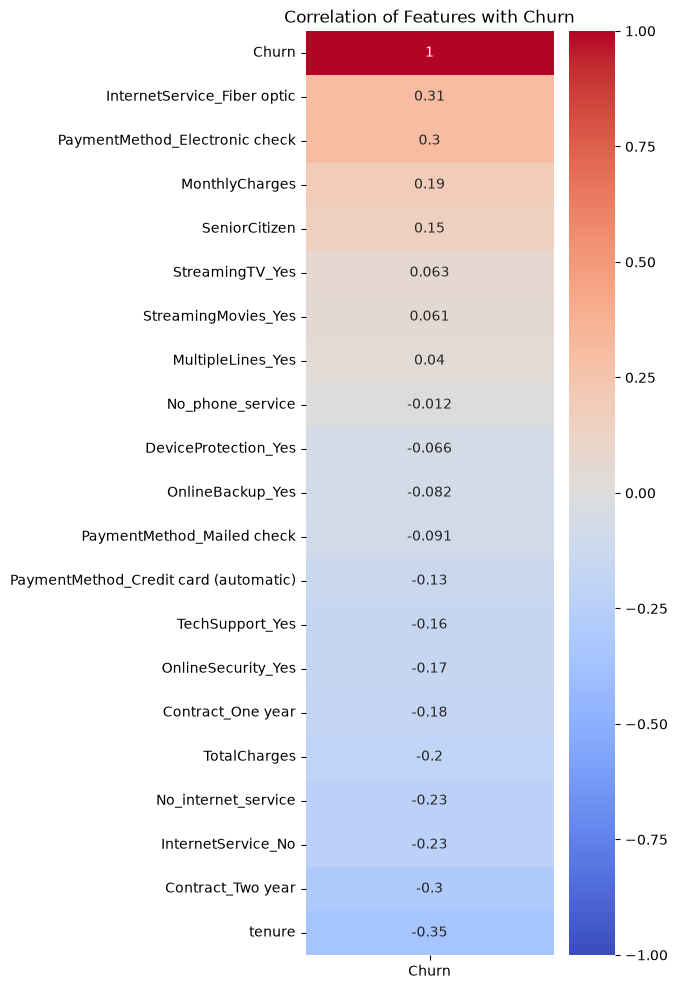

In [ ]:
# Compute correlation matrix only for numeric columns
corr_matrix = df.corr(numeric_only=True)

# Focus on correlation with Churn
churn_corr = corr_matrix[['Churn']].sort_values(by='Churn', ascending=False)

# Plot heatmap
plt.figure(figsize=(4, 12))
sns.heatmap(churn_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Features with Churn')
plt.show()


Negative (lower value → less likely to churn):

- tenure (-0.35) → Customers who stay longer are less likely to churn.
- Contract_Two year (-0.30) → Customers on long-term contracts churn much less.
- Contract_One year (-0.18) → Same trend but weaker than two-year contracts.

Positive (higher value → more likely to churn):

- InternetService_Fiber optic (+0.31) → Fiber optic users churn more in this dataset.
- PaymentMethod_Electronic check (+0.30) → Customers paying electronically via check churn more.

## Look for multicolinearity (VIF)

In [ ]:
# Run VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

# Remove rows with missing or infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by='VIF', ascending=False)

print(vif_data)

C:\Users\amans\AppData\Local\Temp\ipykernel_12956\3055109083.py:12: UserWarning: The design matrix is poorly conditioned (condition number=9.27e+15). VIF calculations may be numerically unstable.
  vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
c:\Users\amans\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\amans\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\amans\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. 

                                  feature           VIF
5                            PhoneService  1.000800e+15
23                    No_internet_service  1.000800e+15
24                       No_phone_service  1.000800e+15
11                     InternetService_No  1.000800e+15
7                          MonthlyCharges  8.660896e+02
10            InternetService_Fiber optic  1.485008e+02
17                    StreamingMovies_Yes  2.415639e+01
16                        StreamingTV_Yes  2.408002e+01
8                            TotalCharges  1.081149e+01
4                                  tenure  7.584453e+00
9                       MultipleLines_Yes  7.289761e+00
14                   DeviceProtection_Yes  6.924754e+00
13                       OnlineBackup_Yes  6.796678e+00
15                        TechSupport_Yes  6.476508e+00
12                     OnlineSecurity_Yes  6.338349e+00
19                      Contract_Two year  2.652328e+00
21         PaymentMethod_Electronic check  1.976

In [ ]:
df.isnull().mean().sort_values(ascending=False)

gender                                   0.0
SeniorCitizen                            0.0
Partner                                  0.0
Dependents                               0.0
tenure                                   0.0
PhoneService                             0.0
PaperlessBilling                         0.0
MonthlyCharges                           0.0
TotalCharges                             0.0
Churn                                    0.0
MultipleLines_Yes                        0.0
InternetService_Fiber optic              0.0
InternetService_No                       0.0
OnlineSecurity_Yes                       0.0
OnlineBackup_Yes                         0.0
DeviceProtection_Yes                     0.0
TechSupport_Yes                          0.0
StreamingTV_Yes                          0.0
StreamingMovies_Yes                      0.0
Contract_One year                        0.0
Contract_Two year                        0.0
PaymentMethod_Credit card (automatic)    0.0
PaymentMet

In [ ]:
# 1. Train standard SVM (SVC) from sklearn
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train_c)

# Evaluate SVM
svm_train_pred = svm_model.predict(X_train_scaled)
svm_test_pred = svm_model.predict(X_test_scaled)

print("=== Support Vector Classifier (Sklearn) ===")
print(f"Training Accuracy: {accuracy_score(y_train_c, svm_train_pred):.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test_c, svm_test_pred):.4f}")


=== Support Vector Classifier (Sklearn) ===
Training Accuracy: 0.8012
Test Accuracy:     0.7989


In [ ]:
# 2. Train Logistic Regression to compare
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train_c)

# Evaluate Logistic Regression
lr_train_pred = lr_model.predict(X_train_scaled)
lr_test_pred = lr_model.predict(X_test_scaled)

print("=== Logistic Regression (Sklearn) ===")
print(f"Training Accuracy: {accuracy_score(y_train_c, lr_train_pred):.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test_c, lr_test_pred):.4f}")


=== Logistic Regression (Sklearn) ===
Training Accuracy: 0.8043
Test Accuracy:     0.8038


In [ ]:
# 3. Train Naive bayes algo to compare
from sklearn.naive_bayes import GaussianNB

# Initialize and train Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train_c)

# Make predictions
nb_train_pred = nb_model.predict(X_train_scaled)
nb_test_pred = nb_model.predict(X_test_scaled)

# Evaluate Naive Bayes
print("=== Gaussian Naive Bayes ===")
print(f"Training Accuracy: {accuracy_score(y_train_c, nb_train_pred):.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test_c, nb_test_pred):.4f}")


=== Gaussian Naive Bayes ===
Training Accuracy: 0.7385
Test Accuracy:     0.7143


In [ ]:
class SVM_classifier():
    def __init__(self, learning_rate=0.001, no_of_iterations=1000, lambda_parameter=0.01):
        self.learning_rate = learning_rate
        self.no_of_iterations = no_of_iterations
        self.lambda_parameter = lambda_parameter
        self.w = None
        self.b = None

    def fit(self, X, Y):
        # Convert inputs to numpy arrays
        X = np.array(X)
        # Convert 0/1 labels to -1/1 labels for standard SVM formulation
        y_label = np.where(Y <= 0, -1, 1)

        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0.0

        # SGD itertions
        for epoch in range(self.no_of_iterations):
            for index, x_i in enumerate(X):
                condition = y_label[index] * (np.dot(x_i, self.w) - self.b) >= 1

                if condition:
                    
                    dw = 2 * self.lambda_parameter * self.w
                    db = 0
                else:
                    # Misclassification step
                    dw = 2 * self.lambda_parameter * self.w - (y_label[index] * x_i)
                    db = y_label[index]

                # Apply updates
                self.w -= self.learning_rate * dw
                self.b -= self.learning_rate * db

    def predict(self, X):
        X = np.array(X)
        output = np.dot(X, self.w) - self.b
        predicted_labels = np.sign(output)
        # Map -1/1 back to 0/1
        return np.where(predicted_labels <= -1, 0, 1)


In [ ]:
# Initialize and train the improved custom classifier
custom_clf = SVM_classifier(learning_rate=0.0001, no_of_iterations=100, lambda_parameter=0.01)
custom_clf.fit(X_train_scaled, y_train_c)

# Make predictions
custom_train_pred = custom_clf.predict(X_train_scaled)
custom_test_pred = custom_clf.predict(X_test_scaled)

# Evaluate performance
print("=== Improved Custom SVM Classifier ===")
print(f"Training Accuracy: {accuracy_score(y_train_c, custom_train_pred):.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test_c, custom_test_pred):.4f}")


=== Improved Custom SVM Classifier ===
Training Accuracy: 0.8023
Test Accuracy:     0.7960


## SAVING THE LOGISTIC REGRESSION MODEL AS ITS THE BEST PERFOMER

In [ ]:

import pandas as pd
import numpy as np
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# 1. Clean raw data
df = df.copy()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.replace([np.inf, -np.inf], np.nan)

if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Handle both raw labels and already encoded values
churn_mapping = {
    "yes": 1,
    "no": 0,
    "1": 1,
    "0": 0
}

df["Churn"] = (
    df["Churn"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(churn_mapping)
)

print("Churn after mapping:")
print(df["Churn"].value_counts(dropna=False))

# Remove rows with missing target only
df = df.dropna(subset=["Churn"])

if df.empty:
    raise ValueError(
        "No rows remain. Check the original Churn labels."
    )

X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

# 2. Split BEFORE fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Identify column types using training data
numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# 4. Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 5. Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# 6. Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# 7. Build the complete pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", lr_model)
])

# 8. Train the entire pipeline
pipeline.fit(X_train, y_train)

# 9. Evaluate
y_proba = pipeline.predict_proba(X_test)[:, 1]

y_pred_035 = (y_proba >= 0.35).astype(int)

print(classification_report(y_test, y_pred_035))

# 10. Save the complete fitted pipeline
artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    pipeline,
    artifact_dir / "churn_pipeline.pkl"
)

print("Saved complete pipeline successfully.")


Churn after mapping:
Churn
0    5163
1    1869
Name: count, dtype: int64
X shape: (7032, 25)
y shape: (7032,)
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1033
           1       0.54      0.72      0.62       374

    accuracy                           0.77      1407
   macro avg       0.71      0.75      0.73      1407
weighted avg       0.79      0.77      0.77      1407

Saved complete pipeline successfully.
